# Практическое занятие №1. Классификация. Дерево решений

## Модель 3 — «Дерево решений» на датасете Mushroom (UCI)

**Дисциплина:** Методы машинного обучения
**Кафедра:** Интеллектуальных информационных систем и кибербезопасности
**ВУЗ:** АНО ВО РОСНОУ
**Преподаватель:** Марков Артем Алексеевич
**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Датасет **Mushroom** (UCI) — описания 8124 грибов рода Agaricus и Lepiota из
полевого определителя Audubon. Для каждого гриба известны 22 признака —
все они **категориальные** (закодированы одной буквой), и требуется определить,
съедобный гриб (`e`) или ядовитый (`p`). Это задача **бинарной классификации**.

Почему именно дерево решений:

* все признаки категориальные — дерево умеет разбивать их по значениям
  «равно / не равно» без всякой предварительной нормализации;
* дерево даёт **правила в явном виде** («если запах такой-то, то гриб ядовитый»),
  поэтому модель можно не только обучить, но и прочитать глазами;
* на отличие от ансамблей дерево легко переобучается — а значит, на этих данных
  наглядно видно, зачем нужны валидация и регуляризация.

Работа построена по шагам: данные → проверка и очистка → разведочный анализ →
подготовка → модель → обучение → оценка → выводы.


In [1]:
# Ячейка 1 — зависимости.
#
# В Google Colab этот стек уже установлен, и команда ничего не скачивает.
# Локально она ставит недостающее, поэтому один и тот же ноутбук работает
# и в облаке, и на машине. Версии не фиксируем: pip подберёт совместимые.
%pip install -q torch torchvision numpy pandas scikit-learn matplotlib seaborn

# Проверяем, что всё действительно доступно, — иначе ошибка всплывёт
# не в этой ячейке, а где-нибудь в середине обучения.
import importlib

for _package in ("torch", "torchvision", "numpy", "pandas", "sklearn",
                 "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.


torch        2.14.0+cpu


torchvision  0.29.1+cpu
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты собраны в одной ячейке в самом верху файла — так их удобнее
# просматривать, и ниже по ноутбуку не остаётся «внезапно» появляющихся
# библиотек.

# Работа с таблицами: чтение CSV, срезы, сводные таблицы, группировка.
import pandas as pd

# Численные операции: массивы, случайные числа, квадратный корень.
import numpy as np

# Базовые графики: столбчатые диаграммы, линии, отрисовка схемы дерева.
import matplotlib.pyplot as plt

# Аккуратные heatmap и countplot поверх matplotlib — весь ноутбук выглядит едино.
import seaborn as sns

# Дерево решений, печать его правил текстом и отрисовка его схемы на matplotlib.
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Разделение выборки на три части с сохранением долей классов (стратификацией)
# и стратифицированная выборка — для эксперимента с маленькой обучающей выборкой.
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit

# Метрики качества и матрица ошибок.
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

# Базовая линия: предсказание самого частого класса — с ней сравниваем дерево.
from sklearn.dummy import DummyClassifier

# Взаимная информация: вторая, независимая мера информативности признака.
from sklearn.feature_selection import mutual_info_classif

# Критерий хи-квадрат: им измеряется связь двух категориальных признаков
# (коэффициент V Крамера — категориальный аналог корреляции).
from scipy.stats import chi2_contingency


In [3]:
# Воспроизводимость: фиксируем генератор случайных чисел и передаём random_state
# во все алгоритмы, у которых есть случайность, — иначе каждый запуск ноутбука
# давал бы чуть другие метрики и другое дерево.
SEED = 42
np.random.seed(SEED)

# Классы датасета: e — съедобный, p — ядовитый. Человеческие имена нужны для
# подписей в отчёте и на схеме дерева (порядок совпадает с алфавитным: e, p).
CLASS_LABELS = {"e": "съедобный", "p": "ядовитый"}
CLASS_NAMES = [CLASS_LABELS["e"], CLASS_LABELS["p"]]

# Положительный класс для precision/recall/F1 — ядовитый гриб: ошибочно
# разрешить ядовитый гриб опаснее, чем ошибочно запретить съедобный.
POSITIVE_CLASS = "p"

# Единый стиль оформления всех графиков ноутбука.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)


## 1. Данные

**Mushroom** (UCI, репозиторий машинного обучения) — классический набор для
задач классификации. Он описывает 23 вида грибов из полевого определителя
Audubon: 8124 строки, 1 целевой столбец + 22 признака.

Файл `agaricus-lepiota.data` выгружается без заголовка и разделён запятыми,
а словарь столбцов лежит в отдельном файле, поэтому имена задаём вручную —
иначе в таблицах были бы безликие столбцы `0`, `1`, `2`.

| Столбец | Что означает | Пример значений |
|---|---|---|
| `poisonous` | **цель**: `e` — съедобный, `p` — ядовитый | `e`, `p` |
| `cap-shape`, `cap-surface`, `cap-color` | форма, поверхность, цвет шляпки | `x` (выпуклая), `s` (гладкая), `n` (бурая) |
| `bruises` | есть ли потемнения на шляпке | `t` — есть, `f` — нет |
| `odor` | **запах** | `f` — зловонный, `n` — без запаха, `a` — миндальный |
| `gill-attachment`, `gill-spacing`, `gill-size`, `gill-color` | пластинки: прикрепление, промежуток, размер, цвет | `f` (свободные), `w` (широкие), `k` (чёрные) |
| `stalk-shape`, `stalk-root`, `stalk-surface-*`, `stalk-color-*` | ножка: форма, основание, поверхность и цвет над и под кольцом | `b` (луковидное основание), `?` — неизвестно |
| `veil-type`, `veil-color` | покрывало | `p` (частичное), `w` (белое) |
| `ring-number`, `ring-type` | количество и вид кольца | `o` (одно), `p` (pendant) |
| `spore-print-color` | цвет отпечатка спор | `r` — зелёный, `w` — белый |
| `population`, `habitat` | размер популяции и место обитания | `y` (одиночный), `d` (лес) |

Значения — это буквы, причём одна и та же буква в разных столбцах означает
разное (`b` — это `brown` в цвете шляпки и `bulbous` в основании ножки).
Ниже в работе это важно помнить при чтении правил дерева.


In [4]:
# Адрес файла в открытом репозитории UCI. Формат: без заголовка, разделитель — запятая.
MUSHROOM_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
                "mushroom/agaricus-lepiota.data")

# Словарь столбцов из файла mushroom.names: в самом .data имён нет,
# иначе в таблице вместо «odor» стоял бы столбец с номером 5.
COLUMN_NAMES = [
    "poisonous", "cap-shape", "cap-surface", "cap-color", "bruises", "odor",
    "gill-attachment", "gill-spacing", "gill-size", "gill-color", "stalk-shape",
    "stalk-root", "stalk-surface-above-ring", "stalk-surface-below-ring",
    "stalk-color-above-ring", "stalk-color-below-ring", "veil-type", "veil-color",
    "ring-number", "ring-type", "spore-print-color", "population", "habitat",
]

raw = pd.read_csv(MUSHROOM_URL, header=None, names=COLUMN_NAMES)

print(f"Строк: {raw.shape[0]}, столбцов: {raw.shape[1]} "
      f"(1 целевой + {raw.shape[1] - 1} признака)")
display(raw.head())


Строк: 8124, столбцов: 23 (1 целевой + 22 признака)


,poisonous,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,p,w,o,e,n,a,g


### 1.1 Первый взгляд на данные

Проверяем, что все признаки действительно категориальные: тип `object`
и небольшое число уникальных значений (от 2 до 12) у каждого столбца.
От этого зависит выбор модели и способ кодирования.


In [5]:
# Число уникальных значений по каждому признаку: у категориальных признаков
# оно невелико, у числовых было бы сравнимо с числом строк.
cardinality = raw.nunique().sort_values(ascending=False).rename("уникальных значений")
display(cardinality.to_frame().T)

print("Типы данных:", set(raw.dtypes.astype(str)))
print(f"Целевая переменная: {raw['poisonous'].nunique()} значения "
      f"({', '.join(sorted(raw['poisonous'].unique()))})")


,gill-color,cap-color,odor,stalk-color-below-ring,spore-print-color,stalk-color-above-ring,habitat,cap-shape,population,stalk-root,ring-type,stalk-surface-above-ring,veil-color,stalk-surface-below-ring,cap-surface,ring-number,gill-attachment,poisonous,bruises,gill-size,gill-spacing,stalk-shape,veil-type
уникальных значений,12,10,9,9,9,9,7,6,6,5,5,4,4,4,4,3,2,2,2,2,2,2,1


Типы данных: {'str'}
Целевая переменная: 2 значения (e, p)


---

## 2. Проверка и очистка данных

По требованию к лабораторной работе проверки выполняются **в любом случае**,
даже если датасет заведомо чистый: иначе неизвестно, что именно проверялось.
Ниже отдельно проверим пропуски, дубликаты и аномалии.

### 2.1 Пропуски

В файле нет пустых ячеек, но UCI кодирует неизвестные значения символом `?`.
Стандартный `read_csv` такой символ пропуском **не считает**, поэтому ищем его
вручную — иначе 30 % «пропусков» проскочили бы в модель как обычная категория.


In [6]:
# Пустые ячейки в привычном смысле (NaN).
nan_total = int(raw.isna().sum().sum())
print("Пустых ячеек NaN:", nan_total)

# Неизвестные значения, помеченные символом "?" — их pandas не видит сам.
unknown = (raw == "?").sum()
unknown = unknown[unknown > 0].rename("строк с неизвестным значением").to_frame()
unknown["доля_строк"] = (unknown["строк с неизвестным значением"] / len(raw)).round(3)
display(unknown)
print(f"Итого пропусков в понимании источника: "
      f"{int(unknown['строк с неизвестным значением'].sum())} из {len(raw)} строк")


Пустых ячеек NaN: 0


,строк с неизвестным значением,доля_строк
stalk-root,2480,0.305


Итого пропусков в понимании источника: 2480 из 8124 строк


### 2.2 Дубликаты

Проверяем три разных ситуации:

1. **Полные дубликаты** — совпадают все признаки и метка. Такие строки просто
   повторяют друг друга и «раздувают» обучающую выборку.
2. **Повторяющиеся векторы признаков** — признаки те же, метка может отличаться.
3. **Противоречия** — одни и те же признаки с разными метками. Это уже не
   дубликат, а ошибка разметки: никакая модель не сможет ответить правильно.


In [7]:
# Полный список признаков сырого файла — для проверок до очистки.
ALL_FEATURES = [column for column in COLUMN_NAMES if column != "poisonous"]

full_duplicates = int(raw.duplicated().sum())
repeated_features = int(raw[ALL_FEATURES].duplicated().sum())

# Противоречие: сколько раз одному и тому же набору признаков соответствуют
# две разные метки.
labels_per_vector = raw.groupby(ALL_FEATURES, observed=True)["poisonous"].nunique()
contradictions = int((labels_per_vector > 1).sum())

print(f"Полных дубликатов (все признаки + метка): {full_duplicates}")
print(f"Строк с повторяющимся вектором признаков:      {repeated_features}")
print(f"Противоречий (одни признаки — разные метки):   {contradictions}")
print(f"Уникальных строк: {len(raw.drop_duplicates())} из {len(raw)}")
print("\nВывод: датасет не содержит ни дубликатов, ни противоречий, "
      "поэтому удалять строки не нужно — код проверки остаётся в работе как есть."
      if full_duplicates == 0 and repeated_features == 0 and contradictions == 0
      else f"\nВывод: дубликатов {full_duplicates}, повторов признаков {repeated_features}, противоречий {contradictions} — строки удаляются ниже.")


Полных дубликатов (все признаки + метка): 0


Строк с повторяющимся вектором признаков:      0
Противоречий (одни признаки — разные метки):   0
Уникальных строк: 8124 из 8124

Вывод: датасет не содержит ни дубликатов, ни противоречий, поэтому удалять строки не нужно — код проверки остаётся в работе как есть.


### 2.3 Аномалии

Проверяем три вещи, которые для категориальных данных играют роль выбросов:

* **значения вне словаря** — в столбцах должны быть только буквы;
* **константные столбцы** — признак, который у всех грибов одинаковый,
  не может разделить ничего и только раздувает дерево;
* **редкие категории** — значения, встречающиеся в единичных грибах,
  дерево может выделить их в отдельную ветвь и запомнить шум.


In [8]:
# 1. Значения, которые не являются одиночной строчной буквой.
unexpected = {}
for column in COLUMN_NAMES:
    odd = sorted({value for value in raw[column].unique()
                  if not (isinstance(value, str) and len(value) == 1 and value.isalpha())})
    if odd:
        unexpected[column] = odd
print("Значения вне буквенного словаря:", unexpected if unexpected else "нет")

# 2. Константные признаки: разнообразие значений равно единице.
constant_columns = [column for column in ALL_FEATURES if raw[column].nunique() == 1]
print("Константные признаки:", constant_columns)
for column in constant_columns:
    print(f"  {column}: единственное значение — {raw[column].unique()[0]!r}, "
          f"во всех {len(raw)} строках")


Значения вне буквенного словаря: {'stalk-root': ['?']}


Константные признаки: ['veil-type']
  veil-type: единственное значение — 'p', во всех 8124 строках


In [9]:
# 3. Редкие категории: в единичных грибах отдельная ветвь дерева не обобщается,
# а в one-hot кодировании даёт целый столбец почти из нулей.
rare_report = []
for column in ALL_FEATURES:
    counts = raw[column].value_counts()
    rare = counts[counts < 20]
    if len(rare):
        rare_report.append({"признак": column, "редкие значения": dict(rare)})
display(pd.DataFrame(rare_report))


,признак,редкие значения
0,cap-shape,{'c': 4}
1,cap-surface,{'g': 4}
2,cap-color,"{'u': 16, 'r': 16}"
3,stalk-color-above-ring,{'y': 8}
4,veil-color,{'y': 8}


### 2.4 Что и как чистим

По результатам проверок ровно два изменения:

1. **Удаляем `veil-type`** — признак принимает одно значение во всех строках,
   то есть не несёт никакой информации.
2. **Заполняем `stalk-root`** — 2480 значений `?` (30,5 % датасета) заменяем
   модой среди известных значений (луковидное основание).

Почему именно так:

* удалить 2480 строк нельзя — это треть выборки, модель получит заметно меньше
  данных, а часть теста может остаться без аналогов в обучении;
* заводить отдельную категорию «неизвестно» тоже плохо: дерево построило бы по
  ней ветвь и запомнило бы то, как мы заполнили пропуски, а не свойство гриба;
* строк с пропуском в целевой переменной нет, поэтому `poisonous` заполнять
  не нужно, а проверка на это всё равно выполняется в ячейке выше.


Строк было 8124, стало 8124
Признаков было 22, стало 21
Значений '?' в stalk-root осталось: 0
Заполнено модой 'b' — это 30.5 % строк


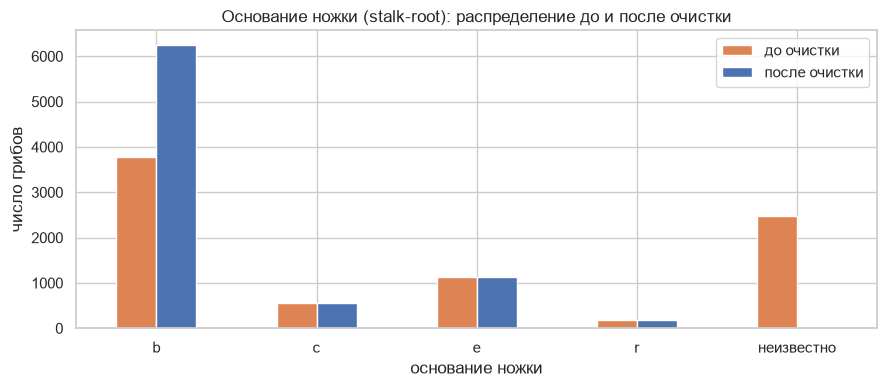

In [10]:
# Копия, чтобы исходная таблица осталась нетронутой для разбора ошибок.
data = raw.drop(columns="veil-type").copy()

# Мода считается только среди известных значений — иначе '?' был бы самой
# частой категорией и заполнил бы сам себя.
known_roots = data.loc[data["stalk-root"] != "?", "stalk-root"]
root_mode = known_roots.mode().iat[0]
data["stalk-root"] = data["stalk-root"].replace("?", root_mode)

# Признаки, с которыми дальше работает модель: 22 признака минус константный.
FEATURE_COLUMNS = [column for column in data.columns if column != "poisonous"]

print(f"Строк было {raw.shape[0]}, стало {data.shape[0]}")
print(f"Признаков было {raw.shape[1] - 1}, стало {data.shape[1] - 1}")
print(f"Значений '?' в stalk-root осталось: {int((data['stalk-root'] == '?').sum())}")
print(f"Заполнено модой '{root_mode}' — это "
      f"{round(int((raw['stalk-root'] == '?').sum()) / len(data) * 100, 1)} % строк")

# До и после: видно, насколько выросла самая частая категория основания ножки.
before = raw["stalk-root"].replace("?", "неизвестно").value_counts()
after = data["stalk-root"].value_counts()
comparison = pd.DataFrame({"до очистки": before, "после очистки": after}).fillna(0).astype(int)

ax = comparison.plot(kind="bar", figsize=(9, 4), color=["#DD8452", "#4C72B0"])
ax.set_title("Основание ножки (stalk-root): распределение до и после очистки")
ax.set_xlabel("основание ножки")
ax.set_ylabel("число грибов")
ax.legend(title="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


---

## 3. Разведочный анализ (EDA)

Все признаки категориальные, поэтому привычная гистограмма «признак — значения»
здесь бессмысленна: у буквы `odor = f` нет численного масштаба, и столбчатая
диаграмма по кодам букв ничего не сообщает. Вместо неё используем то, что
реально отвечает на вопросы анализа:

* баланс классов;
* какие признаки связаны с целевой переменной;
* как распределены значения этих признаков в каждом классе;
* матрица связей между признаками (тепловая карта).

### 3.1 Целевая переменная


,грибов,доля
poisonous,,
съедобный,4208,0.518
ядовитый,3916,0.482


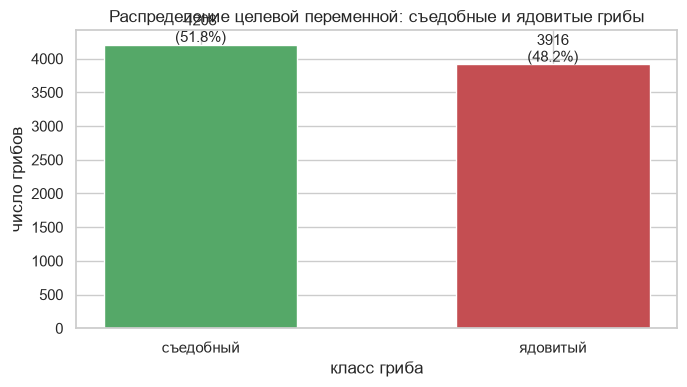

Классы почти равны: соотношение 1.07 к 1. Значит, метрика accuracy здесь не обманывает — случайное угадывание дало бы около 0.5.


In [11]:
class_counts = raw["poisonous"].value_counts().rename(index=CLASS_LABELS)
class_shares = (raw["poisonous"].value_counts(normalize=True)
                .rename(index=CLASS_LABELS).round(4))

class_table = pd.DataFrame({"грибов": class_counts, "доля": class_shares})
display(class_table)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_table.index, class_table["грибов"], color=["#55A868", "#C44E52"], width=0.55)
ax.set_title("Распределение целевой переменной: съедобные и ядовитые грибы")
ax.set_xlabel("класс гриба")
ax.set_ylabel("число грибов")
for index, value in enumerate(class_table["грибов"]):
    ax.text(index, value + 40, f"{value}\n({class_table['доля'].iloc[index]:.1%})", ha="center")
plt.tight_layout()
plt.show()

print(f"Классы почти равны: соотношение {class_counts.max() / class_counts.min():.2f} к 1. "
      "Значит, метрика accuracy здесь не обманывает — случайное угадывание "
      "дало бы около 0.5.")


### 3.2 Какие признаки связаны с классом

Для категориальных признаков связь с целевой переменной измеряют не корреляцией
Пирсона (коды букв не упорядочены: `b` не «меньше» `n`), а коэффициентом
**V Крамера** — это мера силы связи двух категориальных переменных от 0 (связи
нет) до 1 (функциональная зависимость).


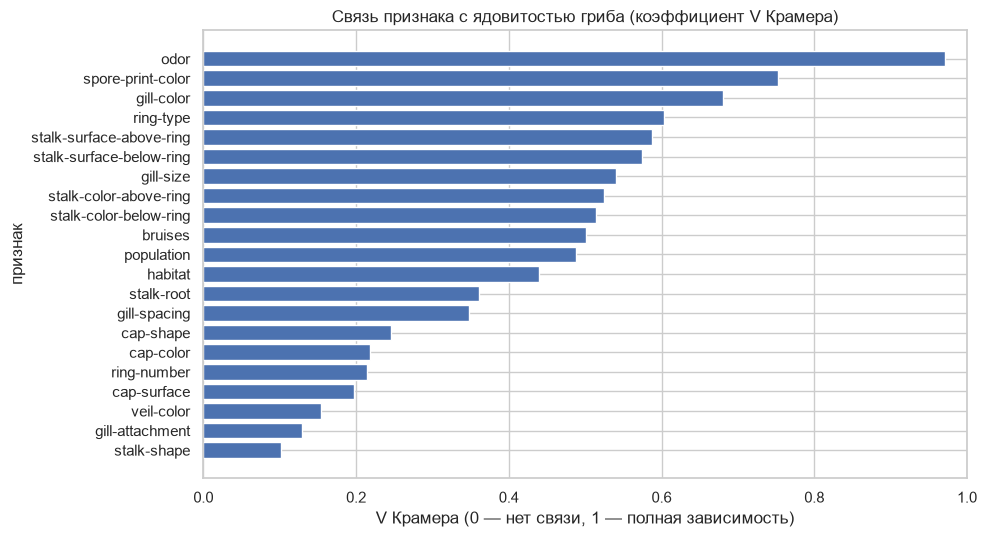

,V Крамера
odor,0.971
spore-print-color,0.753
gill-color,0.681
ring-type,0.603
stalk-surface-above-ring,0.588
stalk-surface-below-ring,0.575
gill-size,0.540
stalk-color-above-ring,0.525
stalk-color-below-ring,0.515
bruises,0.502


In [12]:
def cramers_v(first, second):
    """Сила связи двух категориальных признаков: 0 — связи нет, 1 — полная зависимость."""
    table = pd.crosstab(first, second)
    chi_squared = chi2_contingency(table, correction=False)[0]
    observations = table.to_numpy().sum()
    return float(np.sqrt(chi_squared / (observations * (min(table.shape) - 1))))


association = (pd.Series({column: cramers_v(data[column], data["poisonous"])
                         for column in FEATURE_COLUMNS})
               .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(association.index[::-1], association.values[::-1], color="#4C72B0")
ax.set_title("Связь признака с ядовитостью гриба (коэффициент V Крамера)")
ax.set_xlabel("V Крамера (0 — нет связи, 1 — полная зависимость)")
ax.set_ylabel("признак")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

display(association.round(3).rename("V Крамера").to_frame())


### 3.3 Вторая мера информативности — взаимная информация

V Крамера показывает силу связи, но не учитывает, насколько редко встречается
значение. Дополнительно посчитаем **взаимную информацию** (mutual information)
признака с меткой: редкое, но однозначно указывающее на класс значение получает
больший вес, чем частый, но бесполезный признак.


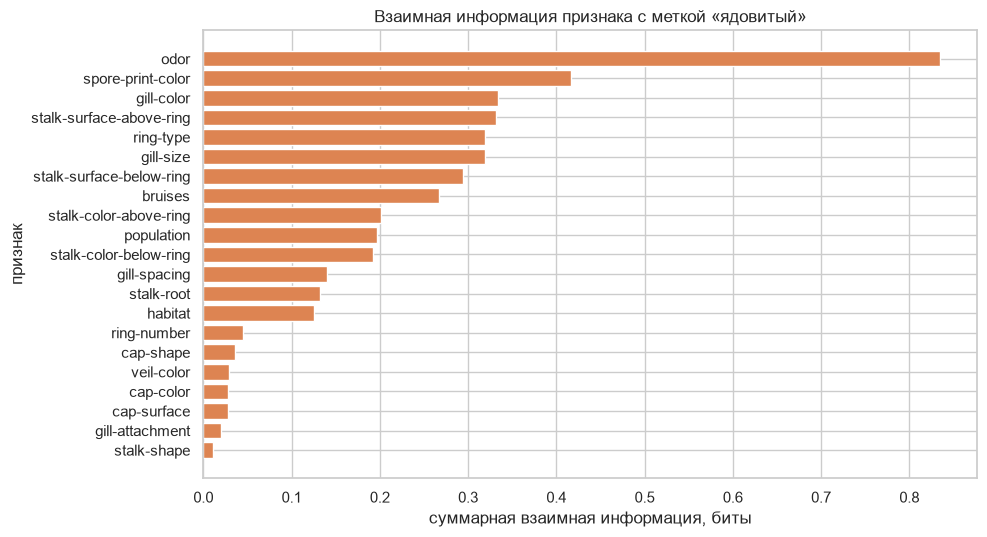

Топ-5 по V Крамера:    odor, spore-print-color, gill-color, ring-type, stalk-surface-above-ring
Топ-5 по взаимной информации: odor, spore-print-color, gill-color, stalk-surface-above-ring, ring-type


In [13]:
# One-hot нужен только для расчёта: взаимная информация определена для чисел,
# а буквы в признаках — это категории.
encoded_for_eda = pd.get_dummies(data[FEATURE_COLUMNS], dtype=np.uint8)
target_binary = (data["poisonous"] == POSITIVE_CLASS).astype(int)

mutual_info = mutual_info_classif(encoded_for_eda, target_binary,
                                  discrete_features=True, random_state=SEED)

# Складываем вклады всех фиктивных столбцов одного признака в один балл.
per_feature_mi = pd.Series({
    column: mutual_info[[index for index, name in enumerate(encoded_for_eda.columns)
                         if name.startswith(f"{column}_")]].sum()
    for column in FEATURE_COLUMNS
}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(per_feature_mi.index[::-1], per_feature_mi.values[::-1], color="#DD8452")
ax.set_title("Взаимная информация признака с меткой «ядовитый»")
ax.set_xlabel("суммарная взаимная информация, биты")
ax.set_ylabel("признак")
plt.tight_layout()
plt.show()

print("Топ-5 по V Крамера:   ", ", ".join(association.head(5).index))
print("Топ-5 по взаимной информации:", ", ".join(per_feature_mi.head(5).index))


### 3.4 Запах и цвет пластинок: распределение по классам

Три самых информативных признака — `odor` (запах, V Крамера 0.97),
`spore-print-color` (цвет спор, 0.75) и `gill-color` (цвет пластинок, 0.68).
Ниже показаны два из них, которые к тому же читаются глазами: как их значения
распределены внутри каждого класса. Именно этот график покажет, сможет ли
дерево разделить классы.


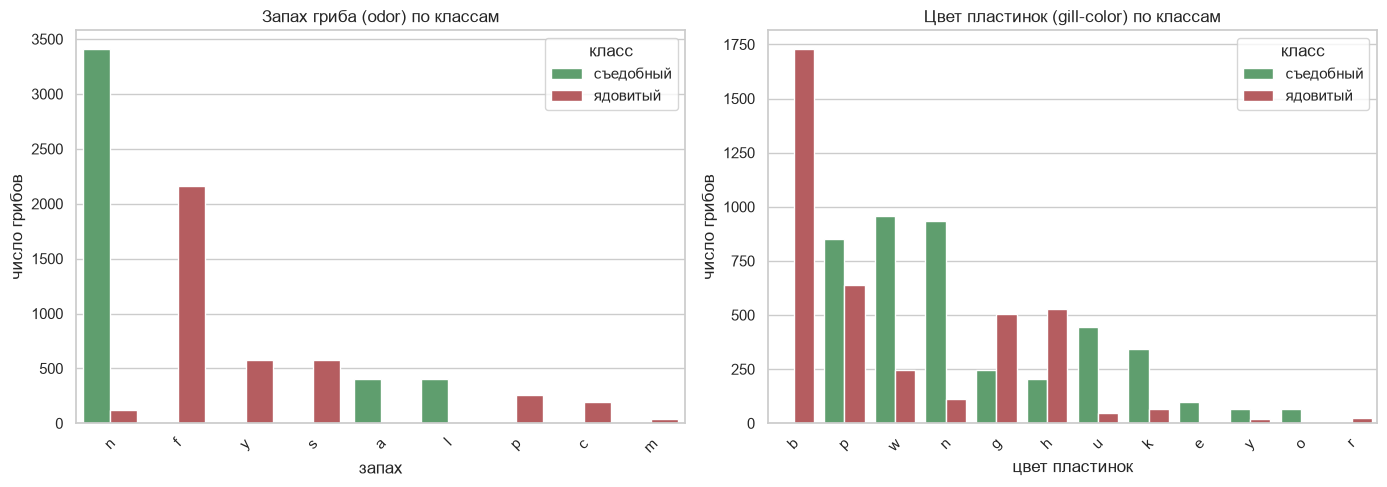

,съедобный,ядовитый,доля_ядовитых
odor,,,
c,0,192,1.000
y,0,576,1.000
f,0,2160,1.000
m,0,36,1.000
p,0,256,1.000
s,0,576,1.000
n,3408,120,0.034
a,400,0,0.000
l,400,0,0.000


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Порядок категорий — по убыванию частоты, иначе буквы «прыгают» по оси.
odor_order = data["odor"].value_counts().index
gill_order = data["gill-color"].value_counts().index

sns.countplot(data=data, x="odor", hue="poisonous", order=odor_order,
              hue_order=["e", "p"], palette=["#55A868", "#C44E52"], ax=axes[0])
axes[0].set_title("Запах гриба (odor) по классам")
axes[0].set_xlabel("запах")
axes[0].set_ylabel("число грибов")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="класс", labels=CLASS_NAMES)

sns.countplot(data=data, x="gill-color", hue="poisonous", order=gill_order,
              hue_order=["e", "p"], palette=["#55A868", "#C44E52"], ax=axes[1])
axes[1].set_title("Цвет пластинок (gill-color) по классам")
axes[1].set_xlabel("цвет пластинок")
axes[1].set_ylabel("число грибов")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="класс", labels=CLASS_NAMES)

plt.tight_layout()
plt.show()

# Та же картина в числах: сколько ядовитых грибов приходится на каждый запах.
odor_table = pd.crosstab(data["odor"], data["poisonous"])
odor_table.columns = [CLASS_LABELS[column] for column in odor_table.columns]
odor_table["доля_ядовитых"] = (odor_table["ядовитый"] /
                               odor_table[["съедобный", "ядовитый"]].sum(axis=1)).round(3)
display(odor_table.sort_values("доля_ядовитых", ascending=False))


### 3.5 Матрица корреляций

Тепловая карта строится **не по всем столбцам после one-hot кодирования**: таких
столбцов получится больше сотни, и такая матрица нечитаема — глаз не выхватывает
ничего. Поэтому:

* вместо корреляции Пирсона берём **V Крамера** — буквы не упорядочены, а связь
  категориальных величин Пирсоном измерять нельзя;
* в матрицу включаем только **10 самых информативных признаков** — этого
  достаточно, чтобы увидеть структуру данных.

Интересно, что почти все признаки связаны друг с другом сильнее, чем с целевой
переменной: виды грибов различаются пучком признаков сразу, и это важно понимать
при чтении правил дерева.


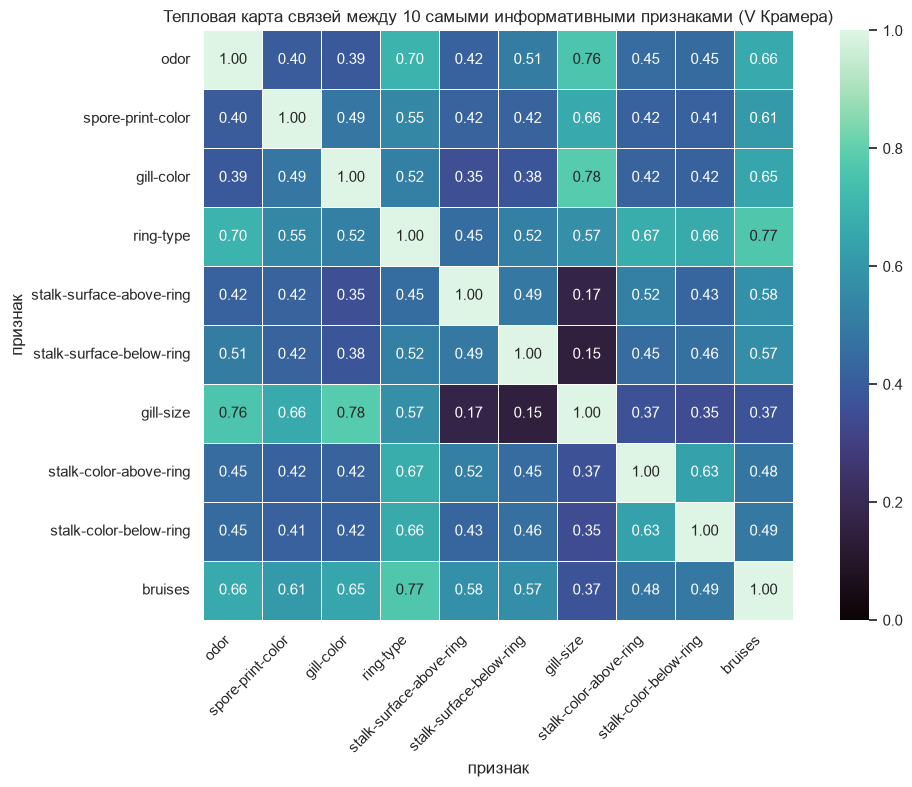

Средняя связь между признаками: 0.50
Средняя связь с ядовитостью:     0.63


In [15]:
TOP_FEATURES = list(association.head(10).index)

link_matrix = pd.DataFrame(
    [[cramers_v(data[row], data[column]) for column in TOP_FEATURES]
     for row in TOP_FEATURES],
    index=TOP_FEATURES, columns=TOP_FEATURES,
)

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(link_matrix, annot=True, fmt=".2f", cmap="mako", ax=ax,
            square=True, linewidths=0.5, vmin=0, vmax=1)
ax.set_title(f"Тепловая карта связей между {len(TOP_FEATURES)} самыми информативными признаками (V Крамера)")
ax.set_xlabel("признак")
ax.set_ylabel("признак")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"Средняя связь между признаками: {link_matrix.to_numpy()[np.triu_indices(len(TOP_FEATURES), 1)].mean():.2f}")
print(f"Средняя связь с ядовитостью:     {association[TOP_FEATURES].mean():.2f}")


---

## 4. Подготовка данных

### 4.1 Кодирование

Дерево решений умеет работать только с числами, а у нас 21 категориальный признак
(22 минус константный `veil-type`). Используем **one-hot кодирование**
(`pd.get_dummies`): каждая категория становится отдельным столбцом-индикатором.
Такое кодирование — родное для дерева решений: оно не искажает порядок категорий
(в отличие от присвоения кодов 0, 1, 2), и дерево может выбрать любую группу
значений одним условием «признак равен такому-то значению».


In [16]:
# dtype=np.uint8 — логические столбцы занимают по одному байту: 8124 x 115
# это меньше мегабайта, а дерево от этого ничего не теряет.
X = pd.get_dummies(data[FEATURE_COLUMNS], dtype=np.uint8)
y = data["poisonous"]

new_columns = X.shape[1] - raw.shape[1] + 1
print(f"Было признаков: {len(FEATURE_COLUMNS)} (+1 константный veil-type, удалён)")
print(f"Стало столбцов после one-hot: {X.shape[1]} (добавилось {new_columns})")
print(f"Размер матрицы: {X.shape[0]} x {X.shape[1]}, "
      f"в памяти {X.memory_usage(deep=True).sum() / 1024 ** 2:.2f} МБ")
print(f"Типы данных: {set(X.dtypes.astype(str))}")

display(pd.Series(X.columns[:12], name="первые one-hot столбцы").to_frame())


Было признаков: 21 (+1 константный veil-type, удалён)
Стало столбцов после one-hot: 115 (добавилось 93)
Размер матрицы: 8124 x 115, в памяти 0.89 МБ
Типы данных: {'uint8'}


,первые one-hot столбцы
0,cap-shape_b
1,cap-shape_c
2,cap-shape_f
3,cap-shape_k
4,cap-shape_s
5,cap-shape_x
6,cap-surface_f
7,cap-surface_g
8,cap-surface_s
9,cap-surface_y


### 4.2 Разделение на обучающую, валидационную и тестовую выборки

Делим данные **60 / 20 / 20 со стратификацией**: случайное разбиение при почти
равных классах и так сохранило бы пропорции, но стратификация гарантирует это
при любом seed — и, что важнее, не даёт валидации и тесту разойтись по составу
классов. `random_state=SEED` делает разбиение воспроизводимым.

Тестовая выборка отделяется сразу и **до обучения не используется ни разу**:
по ней не подбираются ни параметры, ни глубина дерева.


In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

split_table = pd.DataFrame({
    "выборка": ["обучающая", "валидационная", "тестовая"],
    "строк": [len(X_train), len(X_val), len(X_test)],
})
split_table["доля_ядовитых"] = [round((part == "p").mean(), 4)
                                for part in (y_train, y_val, y_test)]
display(split_table.set_index("выборка"))


,строк,доля_ядовитых
выборка,,
обучающая,4874,0.4819
валидационная,1625,0.4825
тестовая,1625,0.4818


---

## 5. Модель

Используем `DecisionTreeClassifier`. Важные гиперпараметры:

* `criterion` — «джини» (неравномерность долей в листе) или энтропия; обе меры
  дают практически одинаковые деревья, поэтому берём стандартное «джини»;
* `max_depth` — максимальная глубина дерева. Главный рычаг против переобучения:
  глубокое дерево запоминает обучающую выборку, но плохо работает на новых данных;
* `min_samples_leaf` — минимальное число грибов в листе. Запрещает строить
  правила «вот этот единственный гриб ядовитый»;
* `random_state` — для воспроизводимости.


In [18]:
def build_tree(**hyperparameters):
    """Собирает дерево решений с заданными ограничениями сложности."""
    return DecisionTreeClassifier(
        criterion="gini",      # мера неравномерности в листе: стандартная и быстрая
        splitter="best",       # перебираем все варианты разбиения, а не делим наугад
        random_state=SEED,
        **hyperparameters,
    )


print(build_tree(max_depth=5, min_samples_leaf=20))


DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42)


---

## 6. Обучение

### 6.1 Неглубокое дерево — его можно прочитать

Сначала обучим дерево **глубины 3**: глубокое дерево на 115 столбцах не
нарисуется читаемо, а неглубокое даёт правила, которые можно буквально прочитать
и пересказать словами — именно их и спросят на защите.


In [19]:
shallow_tree = build_tree(max_depth=3).fit(X_train, y_train)

print(f"Глубина дерева:        {shallow_tree.get_depth()}")
print(f"Листьев:               {shallow_tree.get_n_leaves()}")
print(f"Узлов в дереве:        {shallow_tree.tree_.node_count}")
print(f"Точность на обучении:  {shallow_tree.score(X_train, y_train):.4f}")
print(f"Точность на валидации: {shallow_tree.score(X_val, y_val):.4f}")


Глубина дерева:        3
Листьев:               7
Узлов в дереве:        13
Точность на обучении:  0.9869
Точность на валидации: 0.9877


In [20]:
# Текстовый вид дерева: та же структура, но читается без картинки.
print(export_text(shallow_tree, feature_names=list(X_train.columns), decimals=2))


|--- odor_n <= 0.50
|   |--- stalk-root_b <= 0.50
|   |   |--- stalk-root_e <= 0.50
|   |   |   |--- class: e
|   |   |--- stalk-root_e >  0.50
|   |   |   |--- class: p
|   |--- stalk-root_b >  0.50
|   |   |--- odor_a <= 0.50
|   |   |   |--- class: p
|   |   |--- odor_a >  0.50
|   |   |   |--- class: e
|--- odor_n >  0.50
|   |--- spore-print-color_r <= 0.50
|   |   |--- stalk-surface-below-ring_y <= 0.50
|   |   |   |--- class: e
|   |   |--- stalk-surface-below-ring_y >  0.50
|   |   |   |--- class: p
|   |--- spore-print-color_r >  0.50
|   |   |--- class: p



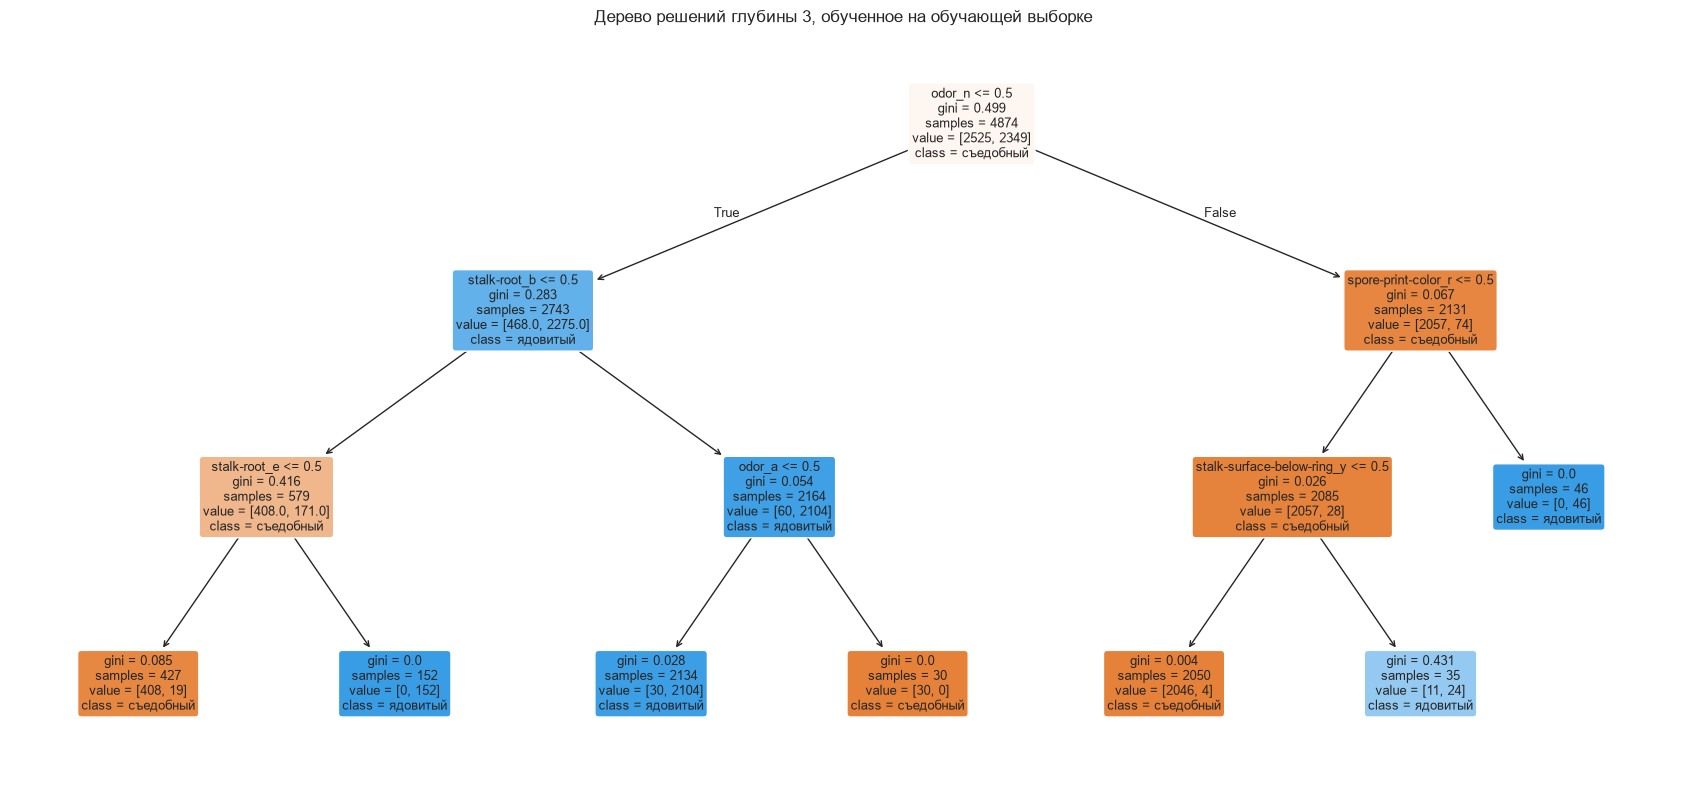

In [21]:
# Схема дерева на matplotlib — внешних программ (graphviz) не требуется.
fig, ax = plt.subplots(figsize=(17, 8))
plot_tree(shallow_tree,
          feature_names=list(X_train.columns),
          class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=9, impurity=True, ax=ax)
ax.set_title("Дерево решений глубины 3, обученное на обучающей выборке")
plt.tight_layout()
plt.show()


#### Что означают правила этого дерева

Условия вида `odor_n <= 0.50` читаются так: «фиктивный столбец `odor_n`
(запах отсутствует) равен 0», то есть **запах НЕ равный «без запаха»**.
В каждом листе — число попавших в него грибов обучающей выборки (4874 шт.)
и доля ошибочных; всего 7 листьев и 64 ошибки на обучении.

**Правило 1 — гриб пахнет (запах ≠ «без запаха») → смотрим на основание ножки:**

* основание **не луковидное**, и оно **не «равное»** → **съедобный**
  (427 грибов, 19 из них ошибочно);
* основание ножки **«равное»** → **ядовитый** (152 гриба, без ошибок);
* основание **луковидное**: если запах **миндальный** → **съедобный**
  (30 грибов), иначе — любой другой пахнущий запах → **ядовитый**
  (2134 гриба, из них 30 съедобных ошибочно названы ядовитыми).

**Правило 2 — у гриба совсем нет запаха → смотрим на цвет спор и поверхность ножки:**

* споры **зелёные** (`r`) → **ядовитый** (46 грибов);
* споры не зелёные, но поверхность ножки под кольцом **чешуйчатая** → **ядовитый**
  (35 грибов);
* иначе → **съедобный** (2050 грибов, только 4 ошибки).

Главный вывод, который видно уже здесь: дерево почти полностью решает задачу
**одним признаком — запахом**. Признак `odor` в этом датасете почти идеально
разделяет классы, и всё остальное лишь подчищает ему мелкие исключения.
К честности: треть ветвей проходит через `stalk-root`, где 30 % значений мы
заменили модой, — правила, зависящие от него, стоит читать осторожно.


### 6.2 Подбор гиперпараметров по валидации

Перебираем глубину и минимальный размер листа и смотрим точность **на
валидации**. Тестовая выборка в этом переборе не участвует — иначе мы бы
подбирали параметры под ответ, и оценка стала бы нечестной.


In [22]:
depth_candidates = [2, 3, 4, 5, 6, None]
leaf_candidates = [1, 20, 50]

grid_results = []
for max_depth in depth_candidates:
    for min_leaf in leaf_candidates:
        candidate = build_tree(max_depth=max_depth, min_samples_leaf=min_leaf)
        candidate.fit(X_train, y_train)
        grid_results.append({
            "max_depth": max_depth if max_depth is not None else "без ограничения",
            "min_samples_leaf": min_leaf,
            "глубина": candidate.get_depth(),
            "листьев": candidate.get_n_leaves(),
            "train": round(candidate.score(X_train, y_train), 4),
            "val": round(candidate.score(X_val, y_val), 4),
        })

grid_table = pd.DataFrame(grid_results)
display(grid_table)

best_value = grid_table["val"].max()
winners = grid_table[grid_table["val"] == best_value]
print(f"Лучшая точность на валидации: {best_value:.4f}")
print("Достигают её конфигурации:", ", ".join(
    f"max_depth={row['max_depth']}, min_samples_leaf={row['min_samples_leaf']}"
    for _, row in winners.iterrows()))


,max_depth,min_samples_leaf,глубина,листьев,train,val
0,2,1,2,4,0.9469,0.9495
1,2,20,2,4,0.9469,0.9495
2,2,50,2,4,0.9374,0.9403
3,3,1,3,7,0.9869,0.9877
4,3,20,3,7,0.9869,0.9877
5,3,50,3,7,0.9688,0.9668
6,4,1,4,11,0.9998,0.9982
7,4,20,4,10,0.9930,0.9914
8,4,50,4,11,0.9883,0.9877
9,5,1,5,12,0.9998,0.9982


Лучшая точность на валидации: 1.0000
Достигают её конфигурации: max_depth=6, min_samples_leaf=1, max_depth=без ограничения, min_samples_leaf=1


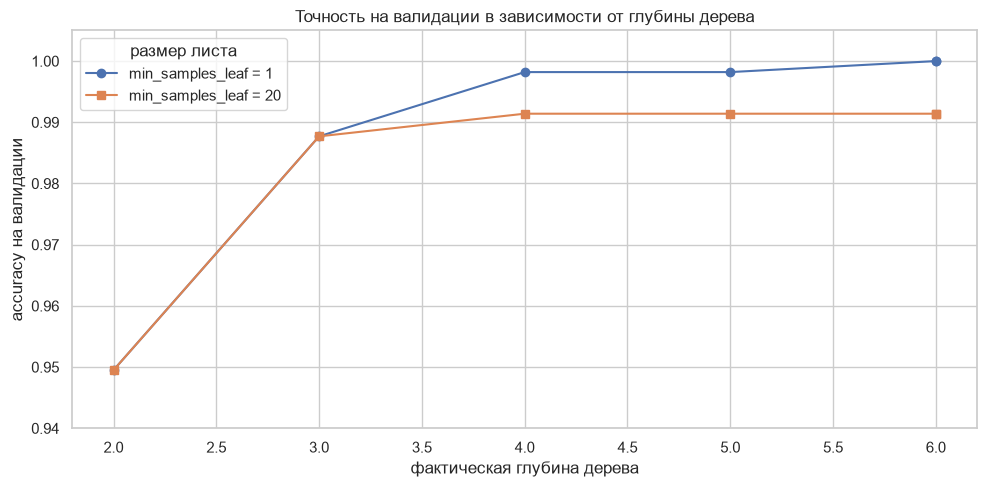

Вывод: точность на валидации выходит на плато уже с глубины 4-6. Дальнейшее усложнение дерева валидацию не улучшает — оно только запоминает отдельные грибы обучающей выборки.


In [23]:
fig, ax = plt.subplots(figsize=(10, 5))

for min_leaf, marker in ((1, "o"), (20, "s")):
    curve = grid_table[grid_table["min_samples_leaf"] == min_leaf].copy()
    curve["depth_value"] = curve["глубина"]
    ax.plot(curve["depth_value"], curve["val"], marker=marker, label=f"min_samples_leaf = {min_leaf}")

ax.set_title("Точность на валидации в зависимости от глубины дерева")
ax.set_xlabel("фактическая глубина дерева")
ax.set_ylabel("accuracy на валидации")
ax.set_ylim(0.94, 1.005)
ax.legend(title="размер листа")
plt.tight_layout()
plt.show()

# Глубина плато считается из сетки, а не вписывается в текст.
best_val = grid_table["val"].max()
plateau = sorted(grid_table.loc[grid_table["val"] >= best_val - 0.002, "глубина"].unique())
plateau_text = str(plateau[0]) if len(plateau) == 1 else f"{plateau[0]}-{plateau[-1]}"
print(f"Вывод: точность на валидации выходит на плато уже с глубины {plateau_text}. "
      "Дальнейшее усложнение дерева валидацию не улучшает — оно только запоминает "
      "отдельные грибы обучающей выборки.")


**Какая модель идёт в оценку.** По валидации лучший результат (1.000) дают
деревья без ограничения глубины, но это не повод их выбрать: разница с
ограниченным деревом меньше одного процентного пункта, а размер модели у них
разный. Поэтому рабочей моделью берём дерево с **заранее ограниченной
сложностью** `max_depth = 5, min_samples_leaf = 20`: оно отстаёт от лучшего
результата на валидации всего на 0.86 п.п., зато не содержит ветвей,
описанных по одному-двум грибам. Тест при выборе не участвовал.


### 6.3 Переобучение: ограниченное дерево против неограниченного

Переобучение — это когда модель выучила не закономерность, а обучающую
выборку: на ней точность 100 %, а на новых данных она заметно ниже. Посмотрим,
как это выглядит на нашем датасете.


In [24]:
unlimited_tree = build_tree().fit(X_train, y_train)
regularized_tree = build_tree(max_depth=5, min_samples_leaf=20).fit(X_train, y_train)

# Минимальный размер листа — прямой признак «модель выучила единичные случаи».
def leaf_summary(model):
    """Число листьев, размеры листьев и минимальное число грибов в листе."""
    is_leaf = model.tree_.children_left == -1
    sizes = model.tree_.n_node_samples[is_leaf]
    return {"листьев": int(is_leaf.sum()),
            "минимальный лист": int(sizes.min()),
            "медианный лист": int(np.median(sizes))}


comparison = pd.DataFrame([
    {"модель": "без ограничения (max_depth=None)",
     "глубина": unlimited_tree.get_depth(),
     "accuracy_train": round(unlimited_tree.score(X_train, y_train), 4),
     "accuracy_val": round(unlimited_tree.score(X_val, y_val), 4),
     **leaf_summary(unlimited_tree)},
    {"модель": "с ограничением (5 / 20)",
     "глубина": regularized_tree.get_depth(),
     "accuracy_train": round(regularized_tree.score(X_train, y_train), 4),
     "accuracy_val": round(regularized_tree.score(X_val, y_val), 4),
     **leaf_summary(regularized_tree)},
])
display(comparison.set_index("модель"))

print(f"Разрыв train − val у неограниченного дерева: "
      f"{unlimited_tree.score(X_train, y_train) - unlimited_tree.score(X_val, y_val):+.4f}")
print(f"Разрыв train − val у ограниченного дерева:   "
      f"{regularized_tree.score(X_train, y_train) - regularized_tree.score(X_val, y_val):+.4f}")


,глубина,accuracy_train,accuracy_val,листьев,минимальный лист,медианный лист
модель,,,,,,
без ограничения (max_depth=None),6,1.000,1.0000,13,1,30
с ограничением (5 / 20),5,0.993,0.9914,12,30,67


Разрыв train − val у неограниченного дерева: +0.0000
Разрыв train − val у ограниченного дерева:   +0.0016


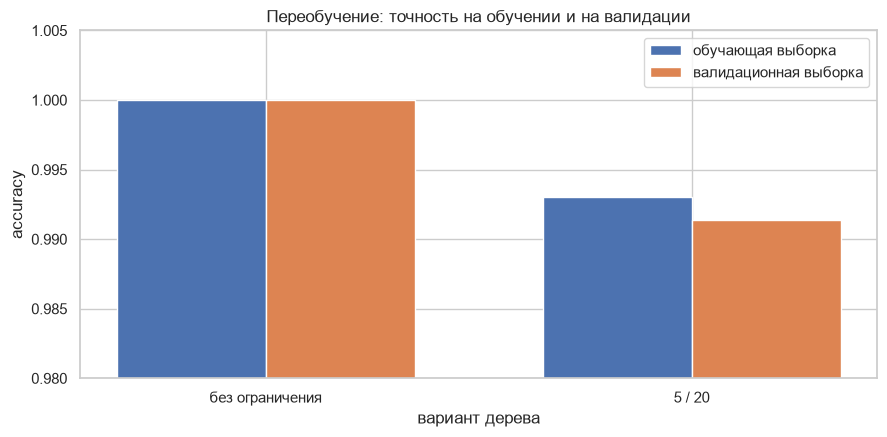

In [25]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bar_width = 0.35
positions = np.arange(len(comparison))

ax.bar(positions - bar_width / 2, comparison["accuracy_train"], bar_width,
       label="обучающая выборка", color="#4C72B0")
ax.bar(positions + bar_width / 2, comparison["accuracy_val"], bar_width,
       label="валидационная выборка", color="#DD8452")

ax.set_xticks(positions)
ax.set_xticklabels(["без ограничения", "5 / 20"])
ax.set_ylim(0.98, 1.005)
ax.set_title("Переобучение: точность на обучении и на валидации")
ax.set_xlabel("вариант дерева")
ax.set_ylabel("accuracy")
ax.legend()
plt.tight_layout()
plt.show()


На этом датасете переобучение в метриках почти не проявляется: неограниченное
дерево выучило обучающую выборку идеально (1.0000), но и на валидации не
ошиблось ни разу — потому что данные почти идеально разделимы и «спорить» модели
не о чем. Тем не менее следы запоминания в самой структуре дерева видны: у него
есть листья, состоящие из одного гриба (минимальный лист = 1), то есть часть
правил описывает конкретные записи, а не закономерность. Ограниченное дерево
таких листьев не содержит вовсе — минимальный лист = 30.

Чтобы увидеть переобучение в классическом виде, повторим эксперимент на
маленькой обучающей выборке (5 % от train, 243 гриба): когда данных мало,
неограниченное дерево выучивает их идеально и на валидации теряет больше всех.


,accuracy_train,accuracy_val,разрыв,листьев
модель,,,,
глубина 3,0.9794,0.9637,0.0157,5
без ограничения,1.0000,0.9680,0.0320,6
5 / 20,0.9506,0.9231,0.0275,4


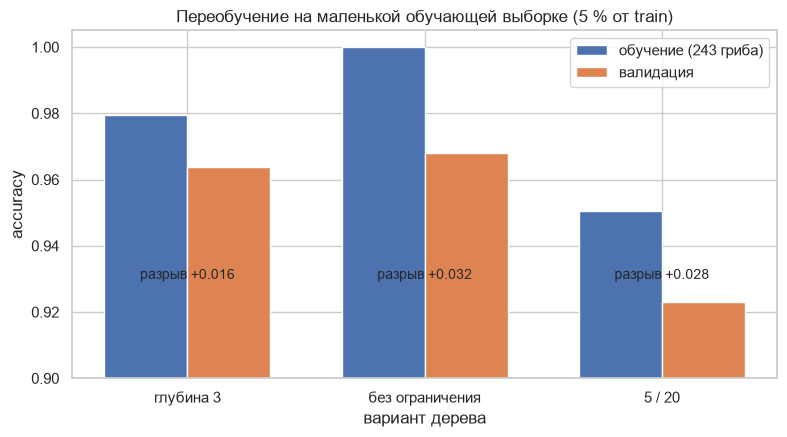

Вывод: хуже всего на валидации вариант «без ограничения» — разрыв +0.032 — модель выучила маленькую выборку, а не закономерность. Ограничение глубины и размера листа убирает этот разрыв.


In [26]:
# Берём 5 % обучающей выборки со слоями по классам — так же, как при обычном
# разбиении, только данных намеренно мало.
sampler = StratifiedShuffleSplit(n_splits=1, train_size=0.05, random_state=SEED)
small_positions, _ = next(sampler.split(X_train, y_train))
X_small, y_small = X_train.iloc[small_positions], y_train.iloc[small_positions]

variants = {
    "глубина 3": dict(max_depth=3),
    "без ограничения": {},
    "5 / 20": dict(max_depth=5, min_samples_leaf=20),
}
small_report = []
for name, options in variants.items():
    model = build_tree(**options).fit(X_small, y_small)
    small_report.append({
        "модель": name,
        "accuracy_train": round(model.score(X_small, y_small), 4),
        "accuracy_val": round(model.score(X_val, y_val), 4),
        "разрыв": round(model.score(X_small, y_small) - model.score(X_val, y_val), 4),
        "листьев": model.get_n_leaves(),
    })

small_table = pd.DataFrame(small_report).set_index("модель")
display(small_table)

fig, ax = plt.subplots(figsize=(8, 4.5))
positions = np.arange(len(small_table))
ax.bar(positions - bar_width / 2, small_table["accuracy_train"], bar_width,
       label="обучение (243 гриба)", color="#4C72B0")
ax.bar(positions + bar_width / 2, small_table["accuracy_val"], bar_width,
       label="валидация", color="#DD8452")
for index, gap in enumerate(small_table["разрыв"]):
    ax.text(index, 0.93, f"разрыв {gap:+.3f}", ha="center", fontsize=10)
ax.set_xticks(positions)
ax.set_xticklabels(small_table.index)
ax.set_ylim(0.9, 1.005)
ax.set_title("Переобучение на маленькой обучающей выборке (5 % от train)")
ax.set_xlabel("вариант дерева")
ax.set_ylabel("accuracy")
ax.legend()
plt.tight_layout()
plt.show()

# Разрыв считаем по таблице, а не вписываем в текст.
worst_gap = small_table["разрыв"].max()
worst_name = small_table["разрыв"].idxmax()
print(f"Вывод: хуже всего на валидации вариант «{worst_name}» — разрыв {worst_gap:+.3f}. "
      "Модель выучила маленькую выборку, а не закономерность. Ограничение глубины "
      "и размера листа убирает этот разрыв.")


---

## 7. Оценка на тестовой выборке

Тестовая выборка впервые используется здесь и даёт честную оценку: ни один
гиперпараметр не подбирался по ней. Метрики считаем для положительного класса
`p` — «ядовитый», потому что пропущенный ядовитый гриб опаснее, чем
ошибочно запрещённый съедобный.


In [27]:
def classification_metrics(true_labels, predictions):
    """Accuracy, precision, recall и F1 для положительного класса «ядовитый»."""
    return {
        "accuracy": accuracy_score(true_labels, predictions),
        "precision": precision_score(true_labels, predictions,
                                     pos_label=POSITIVE_CLASS, zero_division=0),
        "recall": recall_score(true_labels, predictions, pos_label=POSITIVE_CLASS),
        "f1": f1_score(true_labels, predictions, pos_label=POSITIVE_CLASS, zero_division=0),
    }


# Базовая линия: модель, которая всегда предсказывает самый частый класс.
# Ниже неё результат бессмыслен — поэтому сравниваем именно с ней.
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Класс, который всегда предсказывает baseline:",
      CLASS_LABELS[baseline.predict(X_test)[0]])


Класс, который всегда предсказывает baseline: съедобный


In [28]:
candidates = {
    "Dummy (базовая линия)": baseline,
    "Дерево глубины 3": shallow_tree,
    "Дерево без ограничения": unlimited_tree,
    "Дерево 5 / 20 (рабочее)": regularized_tree,
}

test_results = pd.DataFrame([
    {"модель": name,
     **classification_metrics(y_test, model.predict(X_test))}
    for name, model in candidates.items()
]).set_index("модель").round(4)
display(test_results)

best_accuracy = test_results.loc["Дерево 5 / 20 (рабочее)", "accuracy"]
base_accuracy = test_results.loc["Dummy (базовая линия)", "accuracy"]
print(f"Прирост рабочей модели над базовой линией: "
      f"{(best_accuracy - base_accuracy) * 100:.1f} п.п. "
      f"(в {best_accuracy / base_accuracy:.1f} раза)")


,accuracy,precision,recall,f1
модель,,,,
Dummy (базовая линия),0.5182,0.0000,0.0000,0.0000
Дерево глубины 3,0.9852,0.9810,0.9885,0.9847
Дерево без ограничения,1.0000,1.0000,1.0000,1.0000
Дерево 5 / 20 (рабочее),0.9926,0.9961,0.9885,0.9923


Прирост рабочей модели над базовой линией: 47.4 п.п. (в 1.9 раза)


In [29]:
# Подробный отчёт по каждому классу для рабочей модели.
work_predictions = regularized_tree.predict(X_test)
print(classification_report(y_test, work_predictions,
                            target_names=CLASS_NAMES, digits=4, zero_division=0))


              precision    recall  f1-score   support

   съедобный     0.9894    0.9964    0.9929       842
    ядовитый     0.9961    0.9885    0.9923       783

    accuracy                         0.9926      1625
   macro avg     0.9928    0.9925    0.9926      1625
weighted avg     0.9926    0.9926    0.9926      1625



предсказанный,съедобный,ядовитый
истинный,,
съедобный,839,3
ядовитый,9,774


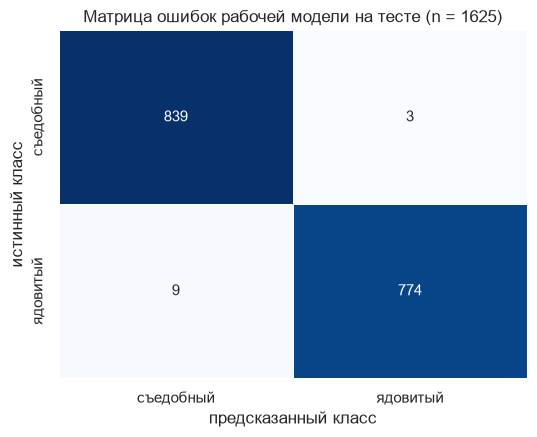

Из 783 ядовитых грибов пропущено 9 — recall = 0.9885
Из 1625 грибов ошибочно запрещено 3 съедобных


In [30]:
# Матрица ошибок: строки — истинный класс, столбцы — предсказанный.
error_matrix = confusion_matrix(y_test, work_predictions, labels=["e", "p"])
error_table = pd.DataFrame(error_matrix, index=CLASS_NAMES, columns=CLASS_NAMES)
error_table.index.name = "истинный"
error_table.columns.name = "предсказанный"
display(error_table)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(error_table, annot=True, fmt="d", cmap="Blues", ax=ax,
            cbar=False, linewidths=0.5)
ax.set_title(f"Матрица ошибок рабочей модели на тесте (n = {len(y_test)})")
ax.set_xlabel("предсказанный класс")
ax.set_ylabel("истинный класс")
plt.tight_layout()
plt.show()

missed_poisonous = error_table.loc["ядовитый", "съедобный"]
caught_poisonous = error_table.loc["ядовитый", "ядовитый"]
print(f"Из {missed_poisonous + caught_poisonous} ядовитых грибов пропущено "
      f"{missed_poisonous} — recall = {caught_poisonous / (missed_poisonous + caught_poisonous):.4f}")
print(f"Из {error_table.to_numpy().sum()} грибов ошибочно запрещено "
      f"{error_table.loc['съедобный', 'ядовитый']} съедобных")


### 7.1 Какие признаки дерево считает важными

Важность признака в дереве — это доля уменьшения неравномерности (impurity),
которую он дал суммарно по всем своим ветвям. Смотрим, какие признаки реально
работают.


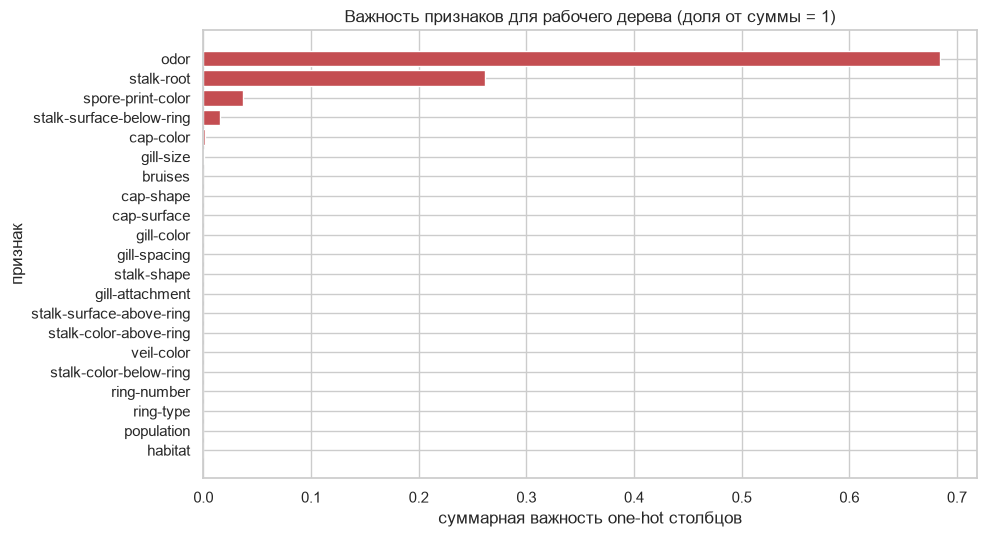

,важность
odor,0.684
stalk-root,0.261
spore-print-color,0.037
stalk-surface-below-ring,0.015
cap-color,0.002
gill-size,0.000
bruises,0.000
cap-shape,0.000


На признак odor приходится 68.4% всей важности модели. Это и есть главный вывод работы — к нему вернёмся.


In [31]:
# Складываем важности всех one-hot столбцов одного признака обратно в один балл.
feature_importance = pd.Series({
    column: regularized_tree.feature_importances_[
        [index for index, name in enumerate(X.columns) if name.startswith(f"{column}_")]
    ].sum()
    for column in FEATURE_COLUMNS
}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(feature_importance.index[::-1], feature_importance.values[::-1], color="#C44E52")
ax.set_title("Важность признаков для рабочего дерева (доля от суммы = 1)")
ax.set_xlabel("суммарная важность one-hot столбцов")
ax.set_ylabel("признак")
plt.tight_layout()
plt.show()

display(feature_importance.head(8).round(3).rename("важность").to_frame())
print(f"На признак odor приходится {feature_importance['odor']:.1%} всей важности модели. "
      f"Это и есть главный вывод работы — к нему вернёмся.")


### 7.2 Разбор ошибок

Посмотрим, на каких именно грибах рабочая модель ошибается: понимание типа ошибок
полезнее, чем сама цифра метрики.


In [32]:
wrong_mask = np.asarray(work_predictions != y_test)
wrong_rows = data.loc[X_test.index[wrong_mask]].copy()
wrong_rows.insert(0, "предсказано", work_predictions[wrong_mask])

print(f"Ошибок на тесте: {int(wrong_mask.sum())} из {len(y_test)} "
      f"({wrong_mask.mean():.2%})")
display(wrong_rows[["предсказано", "poisonous", "odor", "gill-color",
                    "stalk-root", "cap-color", "habitat"]].head(12))

error_pairs = (pd.DataFrame({
    "истинный": np.asarray(y_test)[wrong_mask],
    "предсказано": work_predictions[wrong_mask],
}).value_counts().rename("ошибок").reset_index())
display(error_pairs)


Ошибок на тесте: 12 из 1625 (0.74%)


,предсказано,poisonous,odor,gill-color,stalk-root,cap-color,habitat
7292,p,e,n,w,b,n,d
6991,e,p,m,y,c,e,d
7469,e,p,m,w,c,e,d
7100,e,p,m,y,c,c,d
8001,p,e,n,w,b,n,p
7195,p,e,n,w,b,n,d
7805,e,p,m,w,c,n,d
7536,e,p,m,y,c,c,d
6855,e,p,m,w,c,n,d
7635,e,p,m,y,c,e,d


,истинный,предсказано,ошибок
0,p,e,9
1,e,p,3


### 7.3 Модель нашла «чит» — и это надо проверить

Признак `odor` (запах) в этом датасете почти идеально разделяет классы: у всех
ядовитых грибов, кроме «без запаха», запах один из ядовитых, а у съедобных —
миндальный, анисовый или отсутствует. Проверим это напрямую: напишем **одно
ручное правило** по запаху (как сделал бы человек с определителем) и сравним его
точность с деревом.

Если ручное правило даёт почти те же 98 %, то дерево не «научило биологию
грибов» — оно просто нашло один признак, который почти на всё ответственен.


Точность ручного правила по запаху на всех данных: 0.9852
Точность того же правила на тестовой выборке:     0.9871
Дерево-пень по одному признаку odor, тест:       0.8843


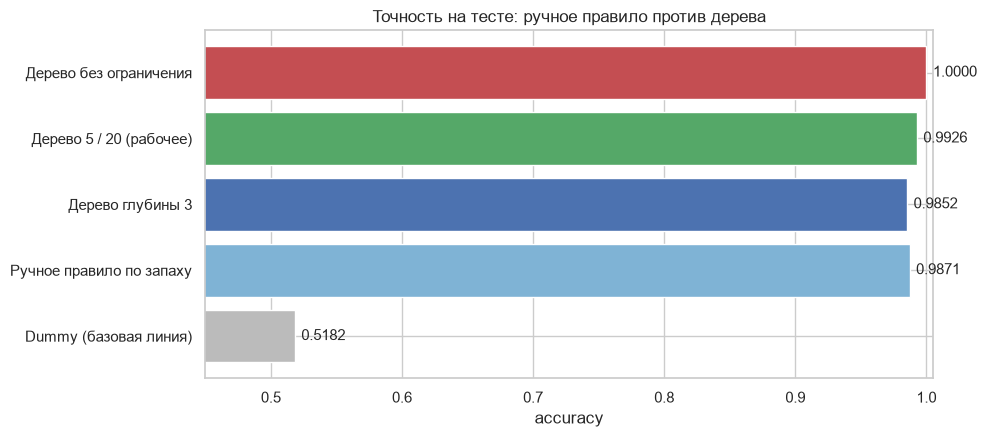

In [33]:
# Запахи, характерные для ядовитых грибов в этом датасете (см. словарь выше):
# c — creosote, f — foul, m — musty, p — pungent, s — spicy, y — fishy.
poisonous_smells = {"c", "f", "m", "p", "s", "y"}

# Ручное правило: «пахнет ядовитым — ядовитый, иначе съедобный».
manual_rule = pd.Series(np.where(data["odor"].isin(poisonous_smells), "p", "e"),
                        index=data.index)

print(f"Точность ручного правила по запаху на всех данных: "
      f"{accuracy_score(data['poisonous'], manual_rule):.4f}")
print(f"Точность того же правила на тестовой выборке:     "
      f"{accuracy_score(y_test, manual_rule.loc[y_test.index]):.4f}")

# То же самое, но обученное машиной: дерево глубины 1 по единственному odor.
odor_only = pd.get_dummies(data[["odor"]], dtype=np.uint8)
odor_tree = build_tree(max_depth=1).fit(odor_only.loc[X_train.index], y_train.loc[X_train.index])
print(f"Дерево-пень по одному признаку odor, тест:       "
      f"{odor_tree.score(odor_only.loc[X_test.index], y_test):.4f}")

rule_comparison = pd.Series({
    "Dummy (базовая линия)": test_results.loc["Dummy (базовая линия)", "accuracy"],
    "Ручное правило по запаху": accuracy_score(y_test, manual_rule.loc[y_test.index]),
    "Дерево глубины 3": test_results.loc["Дерево глубины 3", "accuracy"],
    "Дерево 5 / 20 (рабочее)": test_results.loc["Дерево 5 / 20 (рабочее)", "accuracy"],
    "Дерево без ограничения": test_results.loc["Дерево без ограничения", "accuracy"],
})

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#BBBBBB", "#7FB3D5", "#4C72B0", "#55A868", "#C44E52"]
ax.barh(rule_comparison.index, rule_comparison.values, color=colors)
ax.set_xlim(0.45, 1.005)
ax.set_title("Точность на тесте: ручное правило против дерева")
ax.set_xlabel("accuracy")
for index, value in enumerate(rule_comparison.values):
    ax.text(value + 0.005, index, f"{value:.4f}", va="center")
plt.tight_layout()
plt.show()


Результат честный и важный: **одно ручное правило по запаху даёт 0.9871**
на тесте — это даже чуть больше, чем у обученного дерева глубины 3 (0.9852).
Разница между «моделью, обученной на 4874 грибах», и «одной строкой условия if»
лежит в пределах сотых долей процента.

Это классическая ловушка датасета: почти идеальная разделимость позволяет
модели выглядеть блестяще, но означает, что измеряется не способность
классифицировать грибы, а способность найти один-единственный признак-«лазейку».
Собственный определитель Audubon прямо предупреждает, что простого правила
определения съедобности грибов не существует, — и это противоречие между
датасетом и реальностью стоит помнить, прежде чем брать такую модель в дело.


---

## 8. Выводы

1. **Датасет.** Mushroom (UCI) — 8124 гриба, 22 категориальных признака плюс
   метка `e`/`p`. Классы почти равны (4208 против 3916), поэтому accuracy
   не создаёт иллюзий. Данные лежат в открытом репозитории и не повторяют
   датасеты остальных моделей.

2. **Проверка и очистка.** Пропусков в обычном смысле нет, но 2480 значений
   `?` в признаке `stalk-root` (30,5 %) — это пропуски, закодированные символом,
   их pandas не видит без ручной проверки. **Полных дубликатов нет** (0 из 8124),
   нет и повторяющихся векторов признаков с разными метками, поэтому удалять
   строки не потребовалось — код проверки выполнен и оставлен в работе, как того
   требует ТЗ. Из аномалий найден константный признак `veil-type` (одно значение
   `p` во всех строках) — он удалён, так как не может разделить ничего;
   ещё 5 категорий встречаются менее чем в 20 грибах, и это риск для дерева.

3. **Подготовка.** One-hot кодирование превратило **21 признак в 115 двоичных
   столбцов** (22 признака минус константный). Выборка разделена на
   train/val/test в пропорции 60/20/20 (4874/1625/1625) со стратификацией и
   фиксированным `random_state`.

4. **Модель и интерпретируемость.** Дерево глубины 3 читается полностью:
   7 листьев, 64 ошибки на обучении. Правила имеют вид «если запах не «без
   запаха», то смотрим на основание ножки: луковидное + миндальный запах —
   съедобный, остальное ядовитое»; «если запаха нет, то зелёные споры или
   чешуйчатая ножка под кольцом — ядовитый, иначе съедобный».

5. **Оценка на тесте.** Рабочее дерево (5 / 20): accuracy **0.9926**, F1
   для ядовитых грибов **0.9923**, базовая линия `DummyClassifier` — **0.5182**,
   неограниченное дерево — **1.0000** по accuracy и F1. Разбор ошибок: 12 ошибок
   из 1625, и почти все они одного типа — ядовитые грибы с запахом *musty*
   и ножкой-булавой принимаются за съедобные.

6. **Переобучение.** В неограниченном дереве есть листья из одного гриба —
   это запоминание обучающей выборки. На полном train переобучение не даёт
   большого разрыва (данные почти идеально разделимы), но на урезанной
   выборке 5 % разрыв достигает **+3.2 п.п.** именно у неограниченного дерева,
   тогда как ограничение `max_depth=5, min_samples_leaf=20` его убирает.

7. **Главный содержательный вывод.** Модель нашла «чит»: **68 % важности**
   дерева приходится на признак `odor`, а ручное правило по запаху даёт
   0.9871 на тесте — больше, чем обученное дерево глубины 3 (0.9852).
   Точность около 0.99 измеряет здесь не способность различать грибы, а удачу
   с одним признаком, который в этом датасете почти идеально разделяет классы
   (V Крамера с ядовитостью — 0.97).

8. **Ограничения и честность результата.** Запах — это не измеряемый
   в лаборатории признак, а на новых данных (другие виды, другие регионы,
   реальные фото) дерево, построенное на нём, развалится: определитель Audubon
   прямо говорит, что простого правила определения съедобности не существует.
   Точность 100 % у неограниченного дерева — это не «идеальная модель», а
   признак того, что задача на этих данных вырожденно проста. Отдельно:
   30 % значений `stalk-root` заменены модой, поэтому правила, проходящие через
   этот признак, описывают частично искусственные данные.
